<a href="https://colab.research.google.com/github/gcc712-lgtm/bigdata/blob/main/week07_5756300_%EA%B9%80%EC%B1%84%EC%9B%90.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7주차 과제
빅데이터프로그래밍 · 통계학과

**이름: 김채원**
**학번: 5756300**

## 과제 내용
은닉층 수와 활성화 함수를 변경하고 학습 결과를 비교합니다.

## 제출 방법
모든 셀을 실행해 출력과 그래프가 보이는 상태로 저장한 뒤 `week07_학번_이름.ipynb` 로 제출합니다.

**런타임 > 런타임 유형 변경 > T4 GPU** 를 먼저 선택하세요.


In [11]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

transform = transforms.ToTensor()
train_set = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_set  = datasets.MNIST("./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False)


device: cuda


## 공통 함수
아래 두 함수를 그대로 써서 모델만 바꿔 비교하세요.


In [16]:
def train_model(model, epochs=5, lr=1e-3):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        hist.append(evaluate(model))
        print(f"  epoch {epoch+1}  test acc {hist[-1][1]:.4f}")
    return model, hist


def evaluate(model):
    model.eval()
    loss_fn = nn.CrossEntropyLoss()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total


## 문제 1. 은닉층 수 비교 (35점)
은닉층이 **1개 · 2개 · 3개**인 MLP를 각각 작성해 5 epoch 학습하고, 시험 정확도를 비교하세요.
은닉층 크기는 128로 통일합니다.


In [13]:
# 답안
class MLP1(nn.Module):
    def __init__(self, hidden1=128, n_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, hidden1)
        self.fc2 = nn.Linear(hidden1, n_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = torch.relu(self.fc1(x))
        return self.fc2(x)

class MLP2(nn.Module):
    def __init__(self, hidden1=128, hidden2=128, n_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.fc3 = nn.Linear(hidden2, n_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

class MLP3(nn.Module):
    def __init__(self, hidden1=128, hidden2=128, hidden3=128, n_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.fc3 = nn.Linear(hidden2, hidden3)
        self.fc4 = nn.Linear(hidden3, n_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        return self.fc4(x)

In [14]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total

In [17]:
print("은닉층 1개")
torch.manual_seed(0)
model1, hist1 = train_model(MLP1(), epochs=5)

print("은닉층 2개")
torch.manual_seed(0)
model2, hist2 = train_model(MLP2(), epochs=5)

print("은닉층 3개")
torch.manual_seed(0)
model3, hist3 = train_model(MLP3(), epochs=5)

은닉층 1개
  epoch 1  test acc 0.9349
  epoch 2  test acc 0.9515
  epoch 3  test acc 0.9626
  epoch 4  test acc 0.9685
  epoch 5  test acc 0.9732
은닉층 2개
  epoch 1  test acc 0.9402
  epoch 2  test acc 0.9588
  epoch 3  test acc 0.9662
  epoch 4  test acc 0.9719
  epoch 5  test acc 0.9736
은닉층 3개
  epoch 1  test acc 0.9456
  epoch 2  test acc 0.9590
  epoch 3  test acc 0.9668
  epoch 4  test acc 0.9711
  epoch 5  test acc 0.9743


층이 늘어날수록 정확도(0.9732 -> 0.9736 -> 0.9743)가 올라갔지만 차이는 매우 적은 수준이다. 이 정도는 초기값이나 학습 순서에 따라 바뀔 수 있다.

## 문제 2. 활성화 함수 비교 (35점)
은닉층 2개 모델에서 활성화 함수를 **ReLU · Sigmoid · Tanh** 로 바꿔 각각 학습하고 결과를 비교하세요.


In [19]:
# 답안
class MLP2Act(nn.Module):
    def __init__(self, act, hidden1=128, hidden2=128, n_classes=10):
        super().__init__()
        self.act = act
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.fc3 = nn.Linear(hidden2, n_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = self.act(self.fc1(x))
        x = self.act(self.fc2(x))
        return self.fc3(x)

print("ReLU")
torch.manual_seed(0)
model_relu, hist_relu = train_model(MLP2Act(torch.relu), epochs=5)

print("Sigmoid")
torch.manual_seed(0)
model_sig, hist_sig = train_model(MLP2Act(torch.sigmoid), epochs=5)

print("Tanh")
torch.manual_seed(0)
model_tanh, hist_tanh = train_model(MLP2Act(torch.tanh), epochs=5)

ReLU
  epoch 1  test acc 0.9402
  epoch 2  test acc 0.9588
  epoch 3  test acc 0.9662
  epoch 4  test acc 0.9719
  epoch 5  test acc 0.9736
Sigmoid
  epoch 1  test acc 0.9160
  epoch 2  test acc 0.9385
  epoch 3  test acc 0.9491
  epoch 4  test acc 0.9582
  epoch 5  test acc 0.9627
Tanh
  epoch 1  test acc 0.9416
  epoch 2  test acc 0.9616
  epoch 3  test acc 0.9682
  epoch 4  test acc 0.9724
  epoch 5  test acc 0.9732


ReLU와 Tanh는 5 epoch 정확도가 0.9736과 0.9732로 거의 같다.
Sigmoid는 모든 epoch에서 가장 낮았고, 5 epoch에서도 ReLU보다 약 1.1%p 낮다. 초반 속도는 Tanh가 1 epoch에서 0.9416으로 가장 빨랐고, sigmoid가 0.9160으로 가장 느렸다.

## 문제 3. 결과 비교표와 그래프 (20점)
문제 1·2의 결과를 하나의 표로 정리하고, 학습 곡선을 한 그래프에 겹쳐 그리세요.

| 모델 | 은닉층 수 | 활성화 | 파라미터 수 | 시험 정확도 |


In [23]:
# 답안
models = [
    ("MLP1",         1, "ReLU",    model1,      hist1),
    ("MLP2-ReLU",         2, "ReLU",    model2,      hist2),
    ("MLP3",         3, "ReLU",    model3,      hist3),
    ("MLP2-Sigmoid", 2, "Sigmoid", model_sig,   hist_sig),
    ("MLP2-Tanh",    2, "Tanh",    model_tanh,  hist_tanh),
]

rows = []
for name, n_hidden, act, m, hist in models:
    rows.append({
        "모델": name,
        "은닉층 수": n_hidden,
        "활성화": act,
        "파라미터 수": sum(p.numel() for p in m.parameters()),
        "시험 정확도": round(hist[-1][1], 4),
    })

pd.DataFrame(rows).set_index("모델")

,은닉층 수,활성화,파라미터 수,시험 정확도
모델,,,,
MLP1,1,ReLU,101770,0.9732
MLP2-ReLU,2,ReLU,118282,0.9736
MLP3,3,ReLU,134794,0.9743
MLP2-Sigmoid,2,Sigmoid,118282,0.9627
MLP2-Tanh,2,Tanh,118282,0.9732


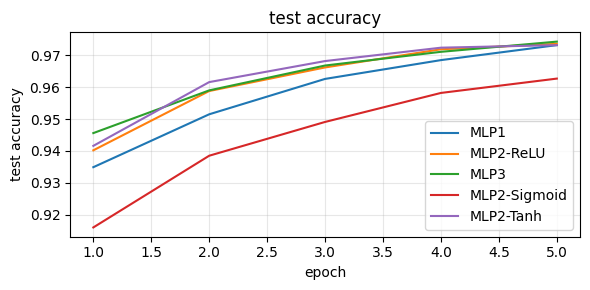

In [42]:
fig, ax = plt.subplots(figsize=(6, 3))

for name, n_hidden, act, m, hist in models:
    te_a = [h[1] for h in hist]
    ax.plot(range(1, len(hist) + 1), te_a, label=name)

ax.set_title("test accuracy"); ax.set_xlabel("epoch"); ax.set_ylabel("test accuracy")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 문제 4. 해석 (10점)
아래 세 가지를 각각 두세 줄로 적으세요.

1. 은닉층을 늘렸을 때 정확도가 어떻게 변했는가 — 계속 좋아지는가
2. Sigmoid가 ReLU보다 느리게 학습되는 이유
3. 가장 좋았던 조합과 그 이유


**답:**

1. 은닉층을 1개에서 3개로 늘리자 정확도가 0.9732 → 0.9736 → 0.9743으로 올랐다. 은닉층 3개에서 가장 높은 정확도인 97.435를 기록했다. 하지만 차이가 0.1%p 안팎이라 계속 좋아진다고 보기는 어렵다.

2. Sigmoid는 입력값이 크거나 작을 때 기울기가 0에 가까워지는 기울기 소실 문제가 발생할 수 있다. 반면, ReLU는 양수 영역에서 기울기가 일정하여 학습이 더 빠르다.

3. 은닉층 3개와 ReLU 조합이 가장 좋았다. 은닉층이 3개일 때 더 복잡한 특징을 학습하여 가장 높은 정확도를 보였고, ReLU는 Sigmoid와 Tanh보다 학습 속도가 빠르고 최종 정확도도 높았기 때문이다.


## 문제 5. 오류 사례 확인 (보너스)
가장 좋았던 모델로 틀리게 예측한 이미지 8장을 그리고, 어떤 숫자를 어떤 숫자로 착각했는지 적으세요.


틀린 개수: 257


/tmp/ipykernel_1638/3676936400.py:26: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1638/3676936400.py:26: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1638/3676936400.py:26: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1638/3676936400.py:26: UserWarning: Glyph 45813 (\N{HANGUL SYLLABLE DAB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print

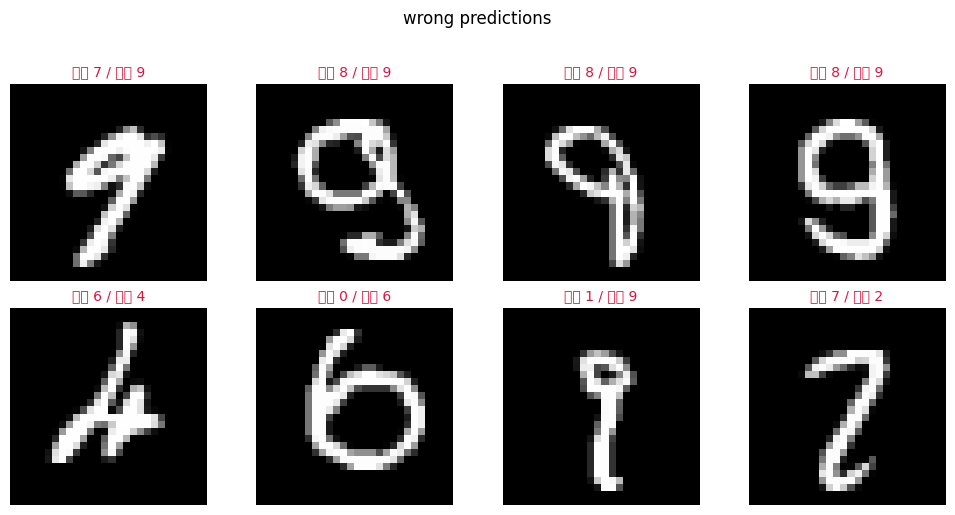

In [44]:
# 답안
model = model3
model.eval()

imgs_list, pred_list, true_list = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        imgs_list.append(x)
        pred_list.append(out.argmax(dim=1).cpu())
        true_list.append(y)

imgs = torch.cat(imgs_list)
pred = torch.cat(pred_list)
true = torch.cat(true_list)

wrong_idx = (pred != true).nonzero().flatten()
print("틀린 개수:", len(wrong_idx))

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, i in zip(axes.flatten(), wrong_idx[:8]):
    ax.imshow(imgs[i].squeeze(), cmap="gray")
    ax.set_title(f"예측 {pred[i].item()} / 정답 {true[i].item()}", fontsize=10, color="crimson")
    ax.axis("off")
plt.suptitle("wrong predictions", y=1.02)
plt.tight_layout(); plt.show()

숫자 9를 1, 7, 8로 착각했다. 이 밖에도 4는 6으로 착각, 6은 0으로 착각, 2는 7로 착각한 경우가 있다.